# Lab01 - sprint 1

**Направление:** Инфохимия  
**Тема:** Статистическая изменчивость характеристик рамановского пика  
**Автор:** Кожеуров Т.А.
**Версия:** 0.1 — создание ноутбука.

Цель: исследовать положение, высоту и интегральную площадь одной полосы при повторных измерениях выбранного вещества. Генератор относится ко второму спринту. Результатов пока нет.

## Оглавление

- [0. Research design & dataset](#setup)
- [Random Variable 01 — Положение пика](#rv1)
- [Random Variable 02 — Высота пика](#rv2)
- [Random Variable 03 — Интегральная площадь](#rv3)
- [Joint analysis](#joint)
- [Lab resume](#resume)

<a id="setup"></a>
## 0. Research design & dataset

### Описание
Единица наблюдения — один спектр выбранного вещества. В фиксированном окне измеряем три характеристики одной полосы. Спектральные каналы не являются независимыми наблюдениями. Вещество и окно выберем после аудита по качеству сигнала, до проверки гипотез.

Конечная учебная совокупность — пригодные спектры выбранного вещества в наборе. Целевая совокупность — повторные измерения в сопоставимых условиях. Независимость повторов пока не установлена.

### Источники
- [Статья](https://www.nature.com/articles/s41597-025-04848-6).
- [Данные](https://springernature.figshare.com/articles/dataset/Open-source_Raman_spectra_of_chemical_compounds_for_active_pharmaceutical_ingredient_development/27931131).

По описанию репозитория: 3510 спектров 32 веществ; проверим после загрузки. Авторские аналитические ноутбуки пока не используем.

### Preparation
Запускайте ячейки сверху вниз сочетанием **Shift+Enter**. Первая ячейка проверяет пакеты и подсказывает команду установки отсутствующих.

In [1]:
import sys
from importlib import metadata

packages = ["numpy", "pandas", "scipy", "matplotlib", "seaborn", "openpyxl"]
missing = []
print("Python:", sys.version.split()[0])
for package in packages:
    try:
        print(f"{package}: {metadata.version(package)}")
    except metadata.PackageNotFoundError:
        missing.append(package)
        print(f"{package}: не установлен")
if missing:
    print("Выполните в отдельной ячейке:")
    print("%pip install " + " ".join(missing))
else:
    print("Все необходимые пакеты доступны.")

Python: 3.14.0
numpy: 2.5.4
pandas: 3.1.0
scipy: 1.18.1
matplotlib: 3.11.2
seaborn: 0.13.2
openpyxl: 3.1.5
Все необходимые пакеты доступны.


После установки пакетов при необходимости перезапустите ядро. Затем выполните следующую ячейку.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
rng = np.random.default_rng(SEED)
DATA_DIR = Path("data")  # Относительно рабочей папки Jupyter.
CSV_PATH = DATA_DIR / "raman_spectra_api_compounds.csv"
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 110})
print("Окружение подготовлено.")
print("Ожидаемый файл:", CSV_PATH.resolve())
print("Файл найден:", CSV_PATH.is_file())

Окружение подготовлено.
Ожидаемый файл: C:\Users\VivoBook Go 15\PycharmProjects\LW_Statistic\raman\data\raman_spectra_api_compounds.csv
Файл найден: True


### Data quality & preprocessing
Следующий шаг: загрузить CSV, проверить сетку, метки, число повторов, пропуски и дубликаты. Данные пока не загружены; `Файл найден: False` ожидаемо.

Высоту и площадь измеряем после обоснованной коррекции фона. Нормирование каждого спектра на собственный максимум уничтожит вариабельность высоты. Стандартизация извлечённых признаков не делает распределение нормальным.

### Загрузка и первичная проверка данных

Загружаем исходные спектры без изменения значений. Проверяем размер
таблицы, названия столбцов и типы данных. Затем определим столбец
с меткой вещества и проверим спектральную сетку.

На этом этапе строки и столбцы не удаляются.

In [3]:
from IPython.display import display

CSV_PATH = Path("data") / "raman_spectra_api_compounds.csv"

if not CSV_PATH.is_file():
    raise FileNotFoundError(
        f"CSV не найден: {CSV_PATH.resolve()}\n"
        f"Рабочая папка Jupyter: {Path.cwd()}\n"
        "Помести файл в папку data или укажи полный путь к нему."
    )

df_raw = pd.read_csv(CSV_PATH)

print(f"Число строк: {df_raw.shape[0]}")
print(f"Число столбцов: {df_raw.shape[1]}")
print(f"Память таблицы: {df_raw.memory_usage(deep=True).sum() / 1024**2:.1f} МБ")

print("\nПервые 5 названий столбцов:")
print(df_raw.columns[:5].tolist())

print("\nПоследние 5 названий столбцов:")
print(df_raw.columns[-5:].tolist())

print("\nКоличество столбцов каждого типа:")
display(df_raw.dtypes.astype(str).value_counts().rename("Количество"))

print("\nФрагмент таблицы: первые и последние столбцы")
preview = pd.concat(
    [df_raw.iloc[:5, :4], df_raw.iloc[:5, -3:]],
    axis=1,
)
display(preview)

Число строк: 3510
Число столбцов: 3277
Память таблицы: 87.9 МБ

Первые 5 названий столбцов:
['150.0', '151.0', '152.0', '153.0', '154.0']

Последние 5 названий столбцов:
['3422.0', '3423.0', '3424.0', '3425.0', 'label']

Количество столбцов каждого типа:


float64    3276
str           1
Name: Количество, dtype: int64


Фрагмент таблицы: первые и последние столбцы


,150.0,151.0,152.0,153.0,3424.0,3425.0,label
0,2975.316162,2954.086182,2934.369385,2913.032959,536.374512,539.313660,"1,3-Dimethyl-2-imidazolidinone"
1,2562.031006,2530.818359,2504.126465,2482.523193,643.311768,453.844269,"1,3-Dimethyl-2-imidazolidinone"
2,3706.918701,3675.912109,3649.161621,3625.712158,5519.607910,5564.967773,"1,3-Dimethyl-2-imidazolidinone"
3,2986.164795,2960.689209,2938.452881,2920.104492,5861.742676,5775.922852,"1,3-Dimethyl-2-imidazolidinone"
4,2739.325195,2721.701660,2702.028320,2679.959717,5089.577637,5415.591309,"1,3-Dimethyl-2-imidazolidinone"


In [4]:
# Отделяем метки веществ от спектральных значений.
# Исходную таблицу df_raw не изменяем.
labels = df_raw["label"]
spectral_columns = df_raw.columns.drop("label")

# Преобразуем названия каналов в числовые координаты.
wavenumbers = spectral_columns.to_numpy(dtype=float)
spectra = df_raw[spectral_columns].to_numpy(dtype=float)

grid_steps = np.diff(wavenumbers)

quality_summary = pd.Series({
    "Количество спектров": len(df_raw),
    "Количество спектральных каналов": len(wavenumbers),
    "Количество веществ": labels.nunique(),
    "Пропуски в метках": int(labels.isna().sum()),
    "Пропуски в интенсивностях": int(np.isnan(spectra).sum()),
    "Бесконечные интенсивности": int(np.isinf(spectra).sum()),
    "Полные дубликаты строк": int(df_raw.duplicated().sum()),
    "Повторяющиеся координаты сетки": int(
        pd.Index(wavenumbers).duplicated().sum()
    ),
})

display(quality_summary.to_frame("Значение"))

print(f"\nДиапазон: {wavenumbers.min():g}–{wavenumbers.max():g} см⁻¹")
print("Сетка строго возрастает:", bool(np.all(grid_steps > 0)))
print("Шаг сетки равен 1 см⁻¹:", bool(np.allclose(grid_steps, 1.0)))

# Проверяем метки, не исправляя их автоматически.
nonmissing_labels = labels.dropna().astype(str)
print(
    "Метки с пробелами по краям:",
    int(nonmissing_labels.ne(nonmissing_labels.str.strip()).sum()),
)
print(
    "Пустые или состоящие из пробелов метки:",
    int(nonmissing_labels.str.strip().eq("").sum()),
)

compound_counts = (
    labels.value_counts(dropna=False)
    .rename_axis("Вещество")
    .reset_index(name="Число спектров")
)

print("\nКоличество спектров по веществам:")
display(compound_counts)

,Значение
Количество спектров,3510
Количество спектральных каналов,3276
Количество веществ,32
Пропуски в метках,0
Пропуски в интенсивностях,0
Бесконечные интенсивности,0
Полные дубликаты строк,5
Повторяющиеся координаты сетки,0



Диапазон: 150–3425 см⁻¹
Сетка строго возрастает: True
Шаг сетки равен 1 см⁻¹: True
Метки с пробелами по краям: 0
Пустые или состоящие из пробелов метки: 0

Количество спектров по веществам:


,Вещество,Число спектров
0,Cyclohexane,145
1,Toluene,127
2,Chloroform,122
3,Benzaldehyde,121
4,Acetone,120
5,Tert-butyl methyl ether,117
6,Acetic acid,113
7,Tert-butanol,113
8,Benzyl bromide,112
9,Dichloromethane,111


### Результаты первичного аудита

Датасет содержит 3510 спектров 32 веществ. Каждый спектр представлен
3276 значениями интенсивности на регулярной сетке 150–3425 см⁻¹
с шагом 1 см⁻¹.

Пропуски, бесконечные значения и повторяющиеся координаты отсутствуют.
Количество измерений на вещество составляет от 100 до 145.
Обнаружено 5 полных повторных строк сверх первых экземпляров.
До выяснения их происхождения дубликаты сохраняются.

Число спектров не тождественно числу независимых образцов:
структуру повторных измерений необходимо учитывать при интерпретации.

In [5]:
# keep=False отмечает все экземпляры повторяющихся строк.
duplicate_members = df_raw.duplicated(keep=False)

# keep="first" отмечает только повторы сверх первого экземпляра.
duplicate_extras = df_raw.duplicated(keep="first")

duplicate_report = pd.concat(
    [
        df_raw.loc[duplicate_members, "label"]
        .value_counts()
        .rename("Всего строк в группах дубликатов"),

        df_raw.loc[duplicate_extras, "label"]
        .value_counts()
        .rename("Повторов сверх первого"),
    ],
    axis=1,
).fillna(0).astype(int)

display(duplicate_report.rename_axis("Вещество"))

print("Позиции всех строк, входящих в группы дубликатов:")
print(np.flatnonzero(duplicate_members.to_numpy()).tolist())

,Всего строк в группах дубликатов,Повторов сверх первого
Вещество,,
Butyl Acetate,4,2
Ethylene Glycol,2,1
Isobutylamine,2,1
Propyl acetate,2,1


Позиции всех строк, входящих в группы дубликатов:
[995, 998, 1013, 1029, 2115, 2209, 2326, 2421, 2946, 3020]


Полные дубликаты образуют пять пар: две пары относятся к Butyl Acetate,
по одной — к Ethylene Glycol, Isobutylamine и Propyl acetate.

Среди четырёх веществ, выбранных для обзорного сравнения, полных
дубликатов строк не обнаружено. Исходные данные сохранены без удаления.

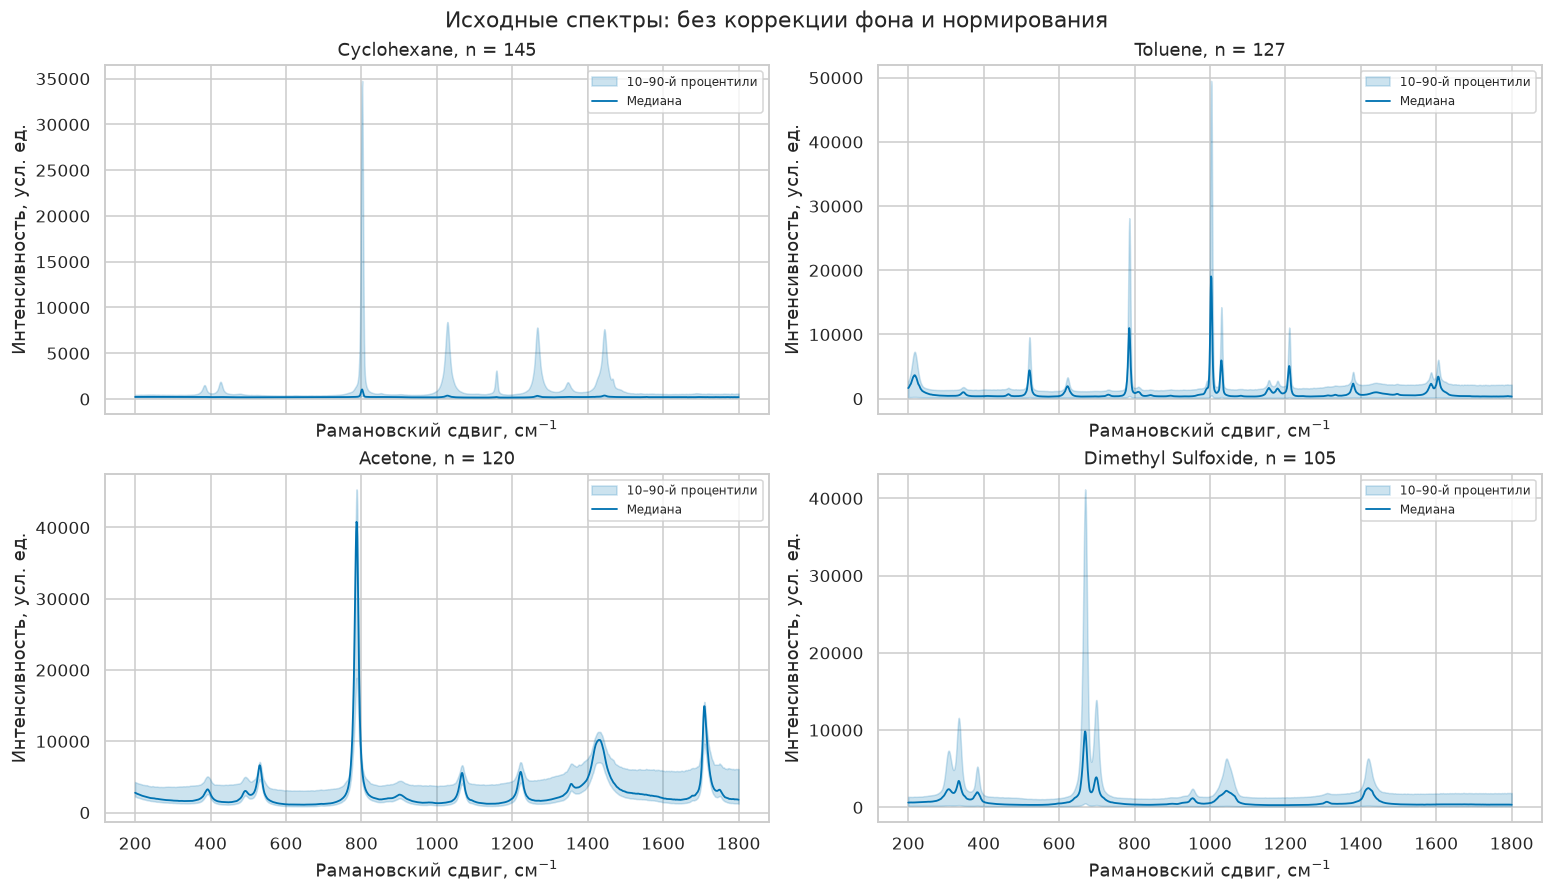

In [6]:
candidates = [
    "Cyclohexane",
    "Toluene",
    "Acetone",
    "Dimethyl Sulfoxide",
]

# На первом обзорном графике рассматриваем только этот диапазон.
# Исходные данные не обрезаем.
region = (wavenumbers >= 200) & (wavenumbers <= 1800)
x = wavenumbers[region]

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "mathtext.fontset": "dejavusans",
})

fig, axes = plt.subplots(
    2, 2,
    figsize=(14, 8),
    sharex=True,
    constrained_layout=True,
)

for ax, compound in zip(axes.flat, candidates):
    mask = labels.eq(compound).to_numpy()
    group = spectra[mask][:, region]

    median_spectrum = np.median(group, axis=0)
    q10, q90 = np.quantile(group, [0.10, 0.90], axis=0)

    ax.fill_between(
        x, q10, q90,
        color="C0", alpha=0.2,
        label="10–90-й процентили",
    )
    ax.plot(
        x, median_spectrum,
        color="C0", linewidth=1.2,
        label="Медиана",
    )

    ax.set_title(f"{compound}, n = {len(group)}")
    ax.set_xlabel(r"Рамановский сдвиг, $\mathrm{см}^{-1}$")
    ax.set_ylabel("Интенсивность, усл. ед.")
    ax.legend(fontsize=8)

fig.suptitle("Исходные спектры: без коррекции фона и нормирования")
plt.show()

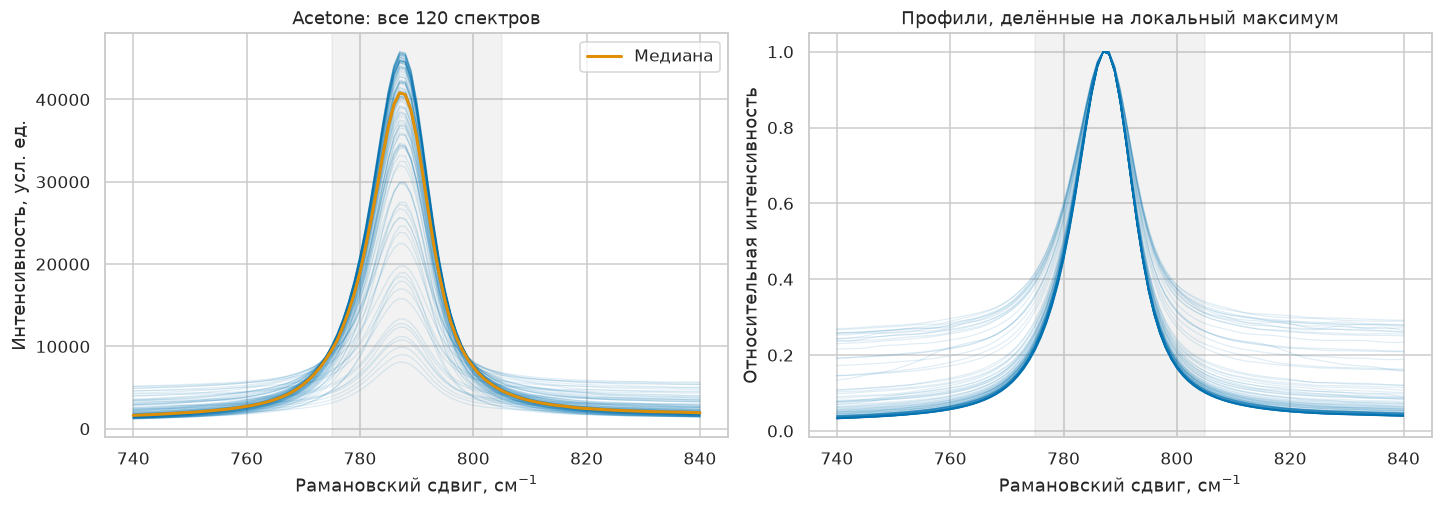

Положения максимумов до коррекции фона:


,Число спектров
"Положение, см⁻¹",
787.0,109
788.0,11


Диапазон исходных высот локального максимума:
8086.6–45801.5 усл. ед.


In [7]:
COMPOUND = "Acetone"

compound_mask = labels.eq(COMPOUND).to_numpy()
compound_positions = np.flatnonzero(compound_mask)
compound_spectra = spectra[compound_mask]

# Обзорное окно вокруг полосы, пока без коррекции фона.
local_region = (wavenumbers >= 740) & (wavenumbers <= 840)
nu_local = wavenumbers[local_region]
intensity_local = compound_spectra[:, local_region]

# Поиск максимума ограничиваем центральной частью окна,
# чтобы не захватывать соседние полосы.
search_region = (nu_local >= 775) & (nu_local <= 805)
nu_search = nu_local[search_region]
intensity_search = intensity_local[:, search_region]

max_indices = np.argmax(intensity_search, axis=1)
raw_peak_positions = nu_search[max_indices]
raw_peak_heights = intensity_search[
    np.arange(len(compound_spectra)), max_indices
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)

# Все спектры в исходных единицах.
axes[0].plot(
    nu_local, intensity_local.T,
    color="C0", alpha=0.12, linewidth=0.8,
)
axes[0].plot(
    nu_local, np.median(intensity_local, axis=0),
    color="C1", linewidth=2, label="Медиана",
)
axes[0].set_title(f"{COMPOUND}: все {len(compound_spectra)} спектров")
axes[0].set_ylabel("Интенсивность, усл. ед.")
axes[0].legend()

# Масштабирование только для визуального сравнения формы.
# Эти значения не используем для измерения высоты и площади.
relative_profiles = intensity_local / raw_peak_heights[:, None]

axes[1].plot(
    nu_local, relative_profiles.T,
    color="C0", alpha=0.12, linewidth=0.8,
)
axes[1].set_title("Профили, делённые на локальный максимум")
axes[1].set_ylabel("Относительная интенсивность")

for ax in axes:
    ax.axvspan(775, 805, color="grey", alpha=0.1)
    ax.set_xlabel(r"Рамановский сдвиг, $\mathrm{см}^{-1}$")

plt.show()

print("Положения максимумов до коррекции фона:")
display(
    pd.Series(raw_peak_positions)
    .value_counts()
    .sort_index()
    .rename_axis("Положение, см⁻¹")
    .to_frame("Число спектров")
)

print("Диапазон исходных высот локального максимума:")
print(f"{raw_peak_heights.min():.1f}–{raw_peak_heights.max():.1f} усл. ед.")

In [8]:
# Боковые участки для оценки фона.
baseline_mask = (
    ((nu_local >= 740) & (nu_local <= 750))
    | ((nu_local >= 830) & (nu_local <= 840))
)

# Центрирование координаты улучшает численную устойчивость.
nu_center = nu_local.mean()
design = np.column_stack([
    np.ones(len(nu_local)),
    nu_local - nu_center,
])

# Для каждого спектра: фон = intercept + slope * (nu - nu_center).
coefficients = np.linalg.lstsq(
    design[baseline_mask],
    intensity_local[:, baseline_mask].T,
    rcond=None,
)[0]

local_baselines = (design @ coefficients).T
corrected_local = intensity_local - local_baselines

# Извлекаем признаки из спектров после коррекции фона.
corrected_search = corrected_local[:, search_region]
peak_indices = np.argmax(corrected_search, axis=1)

peak_positions = nu_search[peak_indices]
peak_heights = corrected_search[
    np.arange(len(corrected_local)), peak_indices
]

area_mask = (nu_local >= 755) & (nu_local <= 820)

# scipy.integrate.trapezoid работает и с более ранними версиями NumPy.
from scipy.integrate import trapezoid

peak_areas = trapezoid(
    corrected_local[:, area_mask],
    x=nu_local[area_mask],
    axis=1,
)

features = pd.DataFrame({
    "source_row": compound_positions,
    "position_cm_inv": peak_positions,
    "height_au": peak_heights,
    "area_au_cm_inv": peak_areas,
})

display(features.head())

print("Положения максимумов после коррекции фона:")
display(
    features["position_cm_inv"]
    .value_counts()
    .sort_index()
    .rename_axis("Положение, см⁻¹")
    .to_frame("Число спектров")
)

print(
    "Число изменившихся положений:",
    int(np.sum(peak_positions != raw_peak_positions)),
)
print("Неположительных высот:", int(np.sum(peak_heights <= 0)))
print("Неположительных площадей:", int(np.sum(peak_areas <= 0)))

,source_row,position_cm_inv,height_au,area_au_cm_inv
0,538,788.0,43756.336897,682137.564062
1,539,787.0,28509.794902,447788.717112
2,540,787.0,42241.647810,664463.880577
3,541,787.0,42253.110201,660196.262744
4,542,787.0,36406.720221,571480.831073


Положения максимумов после коррекции фона:


,Число спектров
"Положение, см⁻¹",
787.0,109
788.0,11


Число изменившихся положений: 0
Неположительных высот: 0
Неположительных площадей: 0


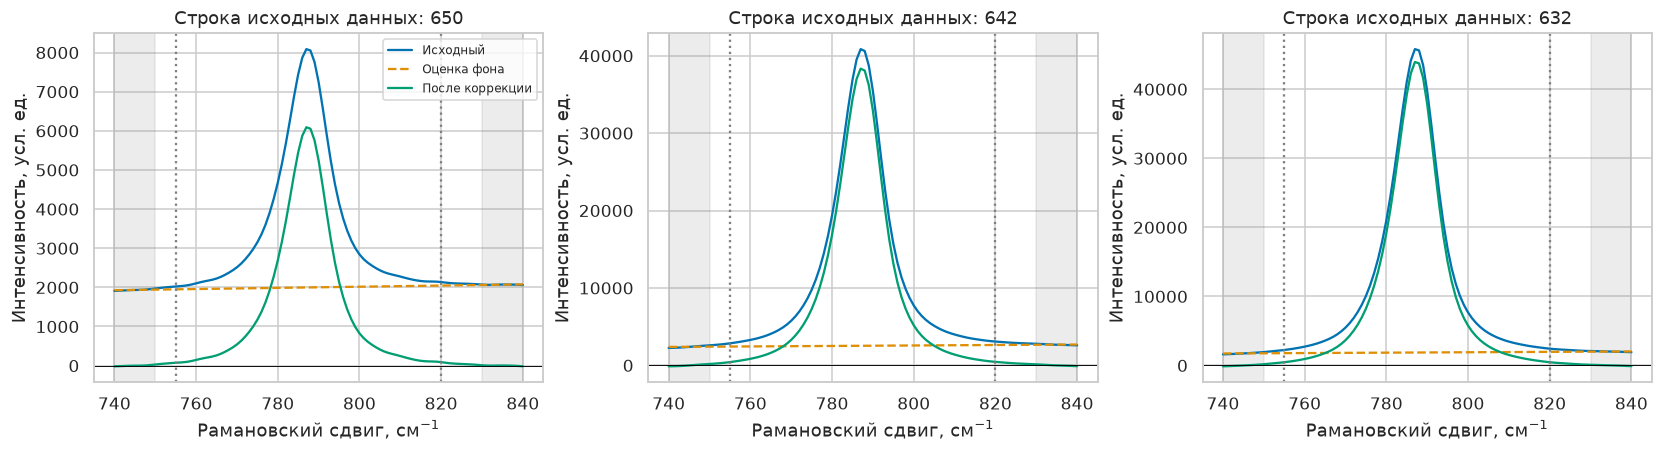

In [9]:
height_order = np.argsort(raw_peak_heights)
example_indices = height_order[
    [0, len(height_order) // 2, len(height_order) - 1]
]

fig, axes = plt.subplots(
    1, 3, figsize=(15, 4),
    constrained_layout=True,
)

for ax, i in zip(axes, example_indices):
    ax.plot(nu_local, intensity_local[i], label="Исходный")
    ax.plot(
        nu_local, local_baselines[i],
        "--", label="Оценка фона",
    )
    ax.plot(
        nu_local, corrected_local[i],
        label="После коррекции",
    )

    ax.axvspan(740, 750, color="grey", alpha=0.15)
    ax.axvspan(830, 840, color="grey", alpha=0.15)
    ax.axvline(755, color="grey", linestyle=":")
    ax.axvline(820, color="grey", linestyle=":")
    ax.axhline(0, color="black", linewidth=0.6)

    ax.set_title(f"Строка исходных данных: {compound_positions[i]}")
    ax.set_xlabel(r"Рамановский сдвиг, $\mathrm{см}^{-1}$")
    ax.set_ylabel("Интенсивность, усл. ед.")

axes[0].legend(fontsize=8)
plt.show()

,Средняя площадь,Медианная площадь,"Медианное изменение, %","Макс. абсолютное изменение, %"
760–815,539182.434,604457.525,-0.979,3.566
755–820 (основное),544718.962,611030.502,0.000,0.000
750–825,547522.725,614236.803,0.494,1.780


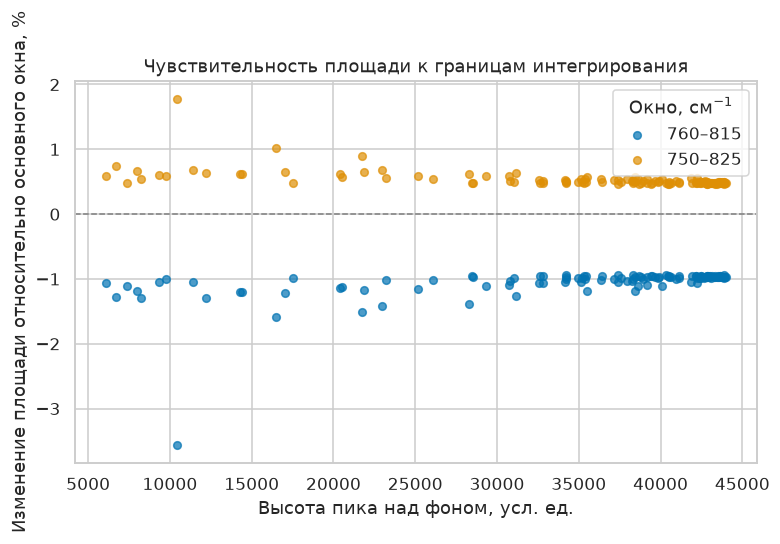

In [10]:
integration_windows = {
    "760–815": (760, 815),
    "755–820 (основное)": (755, 820),
    "750–825": (750, 825),
}

areas_by_window = pd.DataFrame(index=features.index)

for name, (left, right) in integration_windows.items():
    mask = (nu_local >= left) & (nu_local <= right)

    areas_by_window[name] = trapezoid(
        corrected_local[:, mask],
        x=nu_local[mask],
        axis=1,
    )

reference_area = areas_by_window["755–820 (основное)"]

# Изменение площади каждого спектра относительно основного окна.
relative_change_pct = (
    areas_by_window.div(reference_area, axis=0) - 1
) * 100

window_summary = pd.DataFrame({
    "Средняя площадь": areas_by_window.mean(),
    "Медианная площадь": areas_by_window.median(),
    "Медианное изменение, %": relative_change_pct.median(),
    "Макс. абсолютное изменение, %": relative_change_pct.abs().max(),
})

display(window_summary.round(3))

# Проверяем также, одинаково ли меняются слабые и сильные сигналы.
fig, ax = plt.subplots(figsize=(8, 4.5))

for name in ["760–815", "750–825"]:
    ax.scatter(
        features["height_au"],
        relative_change_pct[name],
        s=25, alpha=0.7, label=name,
    )

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Высота пика над фоном, усл. ед.")
ax.set_ylabel("Изменение площади относительно основного окна, %")
ax.set_title("Чувствительность площади к границам интегрирования")
ax.legend(title=r"Окно, $\mathrm{см}^{-1}$")
plt.show()

### Первичная проверка извлечения признаков

После локальной линейной коррекции фона все 120 спектров ацетона
имеют положительные высоты и площади выбранной полосы.

Положение максимума не изменилось после коррекции: 109 наблюдений
приходятся на 787 см⁻¹, 11 — на 788 см⁻¹. В дальнейшем положение
рассматривается как дискретная величина на исходной спектральной сетке.

Площадь определяется интегрированием скорректированного сигнала
в фиксированном окне 755–820 см⁻¹ (это площадь в заданном окне,
а не оценка полной площади полосы на неограниченном диапазоне).

При сужении окна до 760–815 см⁻¹ медианное изменение площади
составило −0,979%, при расширении до 750–825 см⁻¹ — +0,494%.
Максимальные абсолютные изменения составили 3,566% и 1,780%
соответственно.

Для дальнейшего анализа зафиксировано окно 755–820 см⁻¹.
Проверка характеризует чувствительность к границам интегрирования
при неизменной оценке фона; неопределённость фоновой коррекции
требует отдельного рассмотрения.

In [11]:
feature_columns = [
    "position_cm_inv",
    "height_au",
    "area_au_cm_inv",
]

feature_names = {
    "position_cm_inv": "Положение, см⁻¹",
    "height_au": "Высота, усл. ед.",
    "area_au_cm_inv": "Площадь, усл. ед. · см⁻¹",
}

summary_rows = []

for column in feature_columns:
    values = features[column]
    q1, q3 = values.quantile([0.25, 0.75])

    summary_rows.append({
        "Величина": feature_names[column],
        "n": values.size,
        "Уникальных": values.nunique(),
        "Среднее": values.mean(),
        "Медиана": values.median(),
        "Дисперсия (ddof=1)": values.var(ddof=1),
        "Ст. отклонение (ddof=1)": values.std(ddof=1),
        "Минимум": values.min(),
        "Q1": q1,
        "Q3": q3,
        "Максимум": values.max(),
        "IQR": q3 - q1,
        "Асимметрия": values.skew(),
        "Эксцесс": values.kurt(),
    })

descriptive_stats = pd.DataFrame(summary_rows).set_index("Величина")

display(descriptive_stats.round(3))

,n,Уникальных,Среднее,Медиана,Дисперсия (ddof=1),Ст. отклонение (ddof=1),Минимум,Q1,Q3,Максимум,IQR,Асимметрия,Эксцесс
Величина,,,,,,,,,,,,,
"Положение, см⁻¹",120,2,787.092,787.000,8.400000e-02,0.290,787.000,787.000,787.000,788.000,0.000,2.866,6.320
"Высота, усл. ед.",120,120,34681.456,38739.920,1.129665e+08,10628.572,6089.761,31138.802,42654.580,43998.517,11515.777,-1.381,0.795
"Площадь, усл. ед. · см⁻¹",120,120,544718.962,611030.502,2.694718e+10,164155.953,96664.666,496277.343,666854.976,686663.140,170577.634,-1.406,0.874


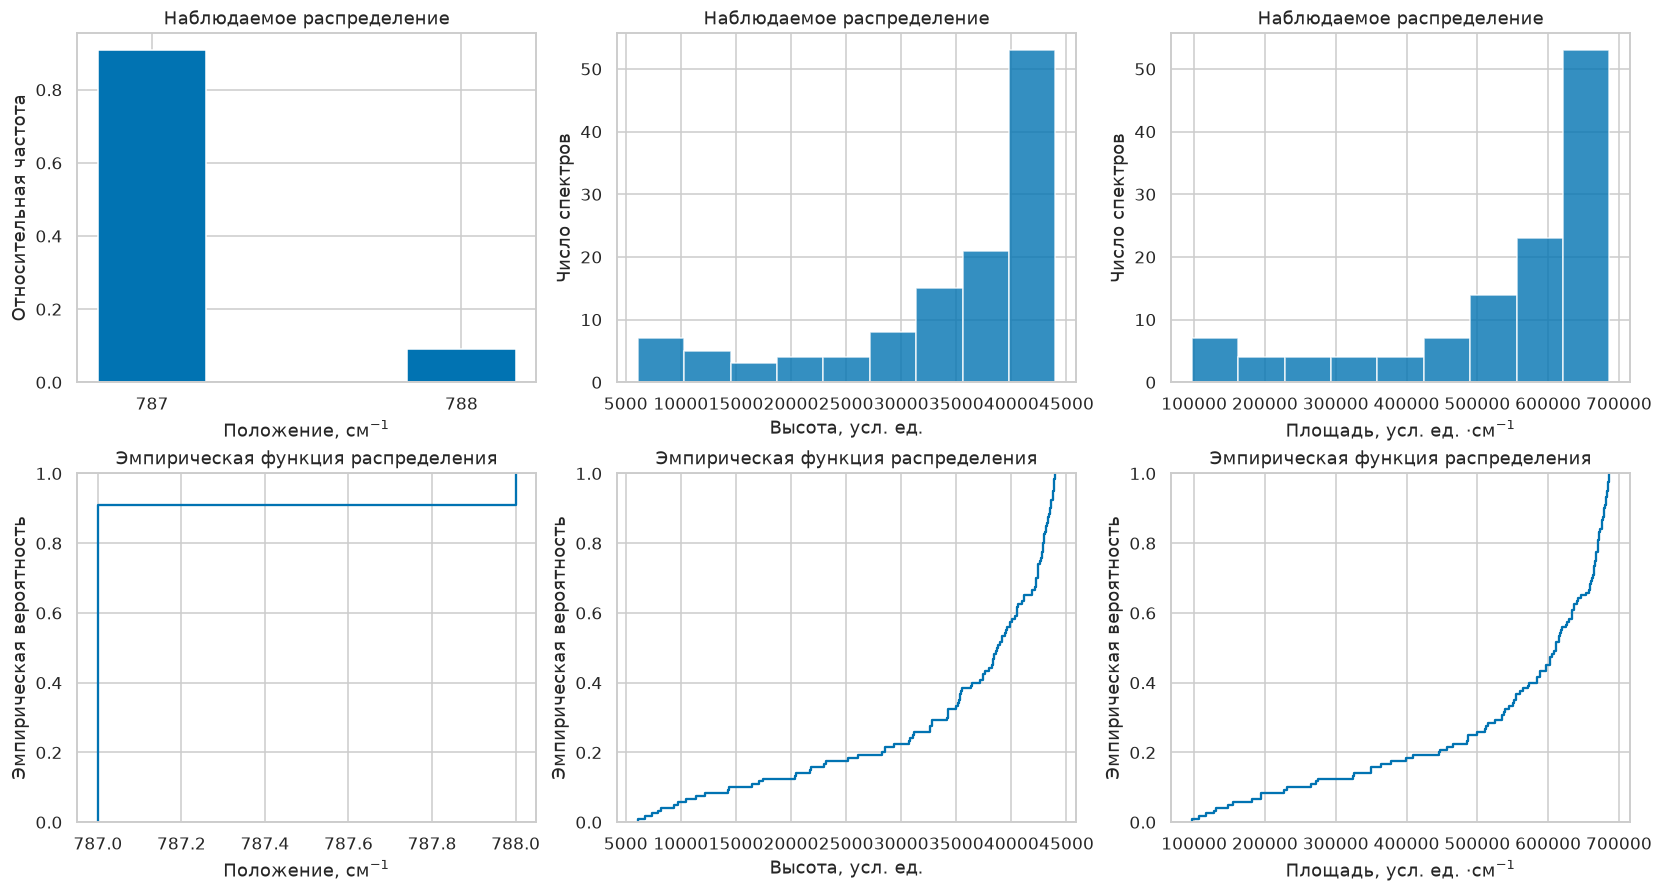

In [12]:
fig, axes = plt.subplots(
    2, 3, figsize=(15, 8),
    constrained_layout=True,
)

axis_labels = {
    "position_cm_inv": r"Положение, $\mathrm{см}^{-1}$",
    "height_au": "Высота, усл. ед.",
    "area_au_cm_inv": r"Площадь, усл. ед. $\cdot\mathrm{см}^{-1}$",
}

for j, column in enumerate(feature_columns):
    values = features[column]

    if column == "position_cm_inv":
        frequencies = values.value_counts(normalize=True).sort_index()

        axes[0, j].bar(
            frequencies.index,
            frequencies.values,
            width=0.35,
        )
        axes[0, j].set_xticks(frequencies.index)
        axes[0, j].set_ylabel("Относительная частота")
    else:
        axes[0, j].hist(
            values, bins="fd",
            edgecolor="white", alpha=0.8,
        )
        axes[0, j].set_ylabel("Число спектров")

    axes[0, j].set_xlabel(axis_labels[column])
    axes[0, j].set_title("Наблюдаемое распределение")

    sns.ecdfplot(x=values, ax=axes[1, j])
    axes[1, j].set_xlabel(axis_labels[column])
    axes[1, j].set_ylabel("Эмпирическая вероятность")
    axes[1, j].set_title("Эмпирическая функция распределения")

plt.show()

<a id="rv1"></a>
## Random Variable 01 — Положение пика

### Description

Исследуемая величина $X$ — положение максимума выбранной полосы
ацетона после локальной линейной коррекции фона. Максимум ищется
в фиксированном диапазоне 775–805 см⁻¹ на исходной сетке с шагом 1 см⁻¹.

Случайный эксперимент — выбор одного повторного измерения ацетона
из рассматриваемой совокупности. Значение $X$ определяется
зарегистрированным спектром и заранее точно неизвестно.

На результат могут влиять флуктуации сигнала, шум и условия измерения.
Детерминированное вычисление максимума не устраняет случайность
исходного измерения. При этом наблюдаемое переключение между каналами
не доказывает физического смещения собственной частоты колебания.

В имеющихся 120 спектрах наблюдаются два значения:
787 см⁻¹ — 109 раз, 788 см⁻¹ — 11 раз.
Рассматриваемая характеристика дискретна из-за способа её измерения.

### EDA & Distribution

Для равновероятного выбора спектра из имеющихся 120 записей
распределение положения задаётся относительными частотами:

$$
P(X=787)=\frac{109}{120}, \qquad
P(X=788)=\frac{11}{120}.
$$

Для возможных будущих измерений эти частоты являются оценками
вероятностей. Отсутствие других значений в выборке не доказывает
невозможность их появления.

В рамках двухточечной модели введём безразмерный индикатор:

$$
B=\frac{X-787\,\mathrm{см}^{-1}}{1\,\mathrm{см}^{-1}},
\qquad B\in\{0,1\}.
$$

Тогда $B$ имеет распределение Бернулли с параметром
$p=P(X=788)$:

$$
P(B=b)=p^b(1-p)^{1-b}, \qquad b\in\{0,1\}.
$$

Его математическое ожидание и дисперсия:

$$
E[B]=p,\qquad \operatorname{Var}(B)=p(1-p).
$$

Следовательно,

$$
E[X]=(787+p)\,\mathrm{см}^{-1},
$$

$$
\operatorname{Var}(X)=p(1-p)\,(1\,\mathrm{см}^{-1})^2.
$$

Оценка параметра по данным:

$$
\widehat p=\frac{11}{120}\approx0.0917.
$$

Медиана положения равна 787 см⁻¹. Межквартильный размах равен нулю,
поскольку оба квартиля совпадают с наиболее частым значением.
Это не означает отсутствия вариабельности: встречается также 788 см⁻¹.

In [13]:
position = features["position_cm_inv"]

# Двухточечная модель применима к текущим наблюдениям.
assert position.isin([787.0, 788.0]).all()

position_indicator = position.eq(788.0).astype(int)

n_position = len(position)
p_hat = position_indicator.mean()

position_model_summary = pd.Series({
    "Число наблюдений": n_position,
    "Частота 787 см⁻¹": 1 - p_hat,
    "Частота 788 см⁻¹": p_hat,
    "Среднее по модели, см⁻¹": 787 + p_hat,
    "Среднее по данным, см⁻¹": position.mean(),
    "Дисперсия по модели, (см⁻¹)²": p_hat * (1 - p_hat),
    "Дисперсия по данным ddof=0, (см⁻¹)²": position.var(ddof=0),
    "Выборочная дисперсия ddof=1, (см⁻¹)²": position.var(ddof=1),
})

display(position_model_summary.to_frame("Значение").round(6))

,Значение
Число наблюдений,120.000000
Частота 787 см⁻¹,0.908333
Частота 788 см⁻¹,0.091667
"Среднее по модели, см⁻¹",787.091667
"Среднее по данным, см⁻¹",787.091667
"Дисперсия по модели, (см⁻¹)²",0.083264
"Дисперсия по данным ddof=0, (см⁻¹)²",0.083264
"Выборочная дисперсия ddof=1, (см⁻¹)²",0.083964


### Independence & Estimations

Оценка вероятности регистрации максимума при 788 см⁻¹:

$$
\widehat p=\frac{1}{n}\sum_{i=1}^{n}B_i
=\frac{11}{120}\approx0.0917.
$$

При независимых одинаково распределённых наблюдениях Бернулли
эта оценка несмещённая:

$$
E[\widehat p]=p,
\qquad
\operatorname{Var}(\widehat p)=\frac{p(1-p)}{n}.
$$

По закону больших чисел $\widehat p$ сходится по вероятности к $p$,
то есть является состоятельной оценкой при указанных предпосылках.
Эмпирическую иллюстрацию сходимости выполним в совместном разделе.

Для оценки неопределённости используем 95%-й интервал Уилсона.
В отличие от простого симметричного нормального интервала,
он остаётся в пределах от 0 до 1 и обычно лучше работает
при небольшом числе наблюдений редкого исхода.

**Ограничение:** независимость и одинаковое распределение повторных
измерений пока не установлены, поэтому интервал интерпретируется
условно, в рамках биномиальной модели. Он относится к возможным
повторным измерениям, а не к уже известной частоте в конечном наборе.

In [14]:
# Интервал Уилсона без установки дополнительных пакетов.
confidence_level = 0.95
z = stats.norm.ppf(1 - (1 - confidence_level) / 2)

denominator = 1 + z**2 / n_position

wilson_center = (
    p_hat + z**2 / (2 * n_position)
) / denominator

wilson_half_width = (
    z / denominator
    * np.sqrt(
        p_hat * (1 - p_hat) / n_position
        + z**2 / (4 * n_position**2)
    )
)

p_lower = wilson_center - wilson_half_width
p_upper = wilson_center + wilson_half_width

estimated_se = np.sqrt(p_hat * (1 - p_hat) / n_position)

print(f"Оценка p: {p_hat:.4f} ({p_hat:.2%})")
print(f"Оценка стандартной ошибки при iid: {estimated_se:.4f}")
print(f"95%-й интервал Уилсона: [{p_lower:.4f}; {p_upper:.4f}]")

# В двухточечной модели E[X] = 787 + p.
print(
    "Соответствующий интервал для среднего положения: "
    f"[{787 + p_lower:.4f}; {787 + p_upper:.4f}] см⁻¹"
)

Оценка p: 0.0917 (9.17%)
Оценка стандартной ошибки при iid: 0.0263
95%-й интервал Уилсона: [0.0520; 0.1567]
Соответствующий интервал для среднего положения: [787.0520; 787.1567] см⁻¹


### Conclusions

В 120 спектрах ацетона максимум выбранной полосы зарегистрирован
при 787 см⁻¹ в 109 случаях и при 788 см⁻¹ в 11 случаях.
Коррекция фона не изменила эти положения.

Среднее положение составляет 787,0917 см⁻¹, выборочное стандартное
отклонение — около 0,290 см⁻¹. Нулевой межквартильный размах
объясняется преобладанием значения 787 см⁻¹ и не означает
отсутствия вариабельности.

Наблюдаемое распределение описано двухточечной моделью.
Оценка вероятности значения 788 см⁻¹ равна 0,0917.
При предположении независимых одинаково распределённых измерений
95%-й интервал Уилсона составляет [0,0520; 0,1567].

Результат характеризует положение зарегистрированного максимума
на дискретной сетке. Он не доказывает физического смещения полосы
и не определяет точность прибора. Зависимость от других признаков
и эмпирическая состоятельность оценок будет рассмотрена в совместном анализе.

<a id="rv2"></a>
## Random Variable 02 — Высота пика

### Description

Случайная величина $Y$ — максимальная интенсивность выбранной
полосы ацетона над оценённым локальным фоном:

$$
Y_i=\max_{\nu\in[775,805]}[I_i(\nu)-\widehat B_i(\nu)].
$$

Единицы измерения — условные единицы интенсивности.
Локальный линейный фон оценивается отдельно для каждого спектра
по участкам 740–750 и 830–840 см⁻¹.

Случайность величины связана с вариабельностью зарегистрированного
сигнала при повторных измерениях. Возможные факторы — шум,
изменения оптической геометрии и эффективности сбора рассеянного света.
Их отдельные вклады по имеющимся данным не установлены.

Высота измеряется без нормирования спектра на собственный максимум.
Все 120 полученных значений положительны.

### EDA & Distribution

Средняя высота составляет 34681,456 усл. ед., медиана —
38739,920 усл. ед., выборочное стандартное отклонение —
10628,572 усл. ед.

Среднее ниже медианы, коэффициент асимметрии равен −1,381.
Гистограмма показывает концентрацию наблюдений в области больших
высот и хвост в сторону малых значений.

Нормальную модель нельзя принимать без проверки. Малые значения
не исключаются автоматически: они могут отражать реальные условия
измерения, а не ошибки данных.



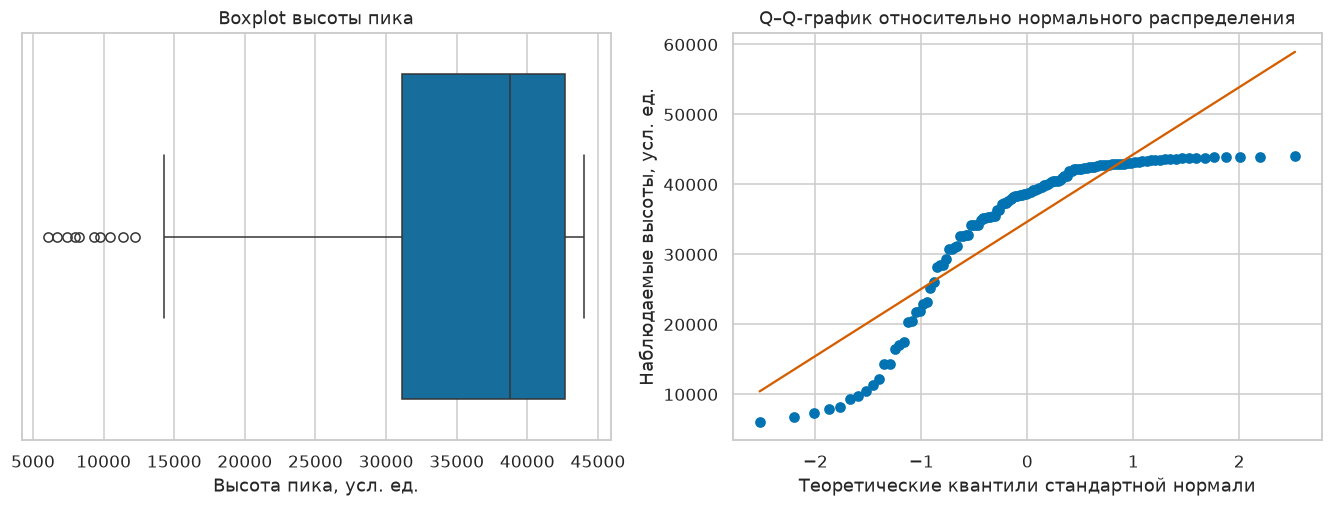

Нижняя граница Тьюки: 13865.14
Верхняя граница Тьюки: 59928.25
Наблюдений за границами: 10 из 120


In [15]:
height = features["height_au"]

fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5),
    constrained_layout=True,
)

sns.boxplot(x=height, ax=axes[0], color="C0")
axes[0].set_xlabel("Высота пика, усл. ед.")
axes[0].set_title("Boxplot высоты пика")

stats.probplot(height, dist="norm", plot=axes[1])
axes[1].set_title("Q–Q-график относительно нормального распределения")
axes[1].set_xlabel("Теоретические квантили стандартной нормали")
axes[1].set_ylabel("Наблюдаемые высоты, усл. ед.")

plt.show()

q1, q3 = height.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outside_fences = (height < lower_fence) | (height > upper_fence)

print(f"Нижняя граница Тьюки: {lower_fence:.2f}")
print(f"Верхняя граница Тьюки: {upper_fence:.2f}")
print(f"Наблюдений за границами: {outside_fences.sum()} из {len(height)}")

#### Стандартизация и проверка нормальности

За нижней границей Тьюки находятся 10 наблюдений из 120 (8,33%).
Их сохраняем: статистическая необычность не доказывает ошибочности.

Для сравнения признаков разных масштабов используем стандартизацию:

$$
Y_i^{\mathrm{std}}=\frac{Y_i-\overline Y}{s_Y},
$$

где $s_Y$ — выборочное стандартное отклонение с ddof=1.
Стандартизованные значения безразмерны, их среднее равно нулю,
а выборочное стандартное отклонение — единице.

Преобразование сохраняет форму распределения и не устраняет
асимметрию. Стандартизованную высоту нельзя заранее считать
стандартной нормальной величиной.

Проверим нормальную модель критерием Шапиро — Уилка:

- $H_0$: наблюдения получены из нормального распределения;
- $H_1$: распределение отличается от нормального;
- уровень значимости $\alpha=0.05$.

Интерпретация p-value предполагает независимые одинаково
распределённые наблюдения. Для повторных спектров эта предпосылка
пока не подтверждена, поэтому результат рассматривается условно.
Проверка является разведочной: она выбрана после просмотра EDA.

Среднее после стандартизации: -0.000000
Стандартное отклонение после стандартизации: 1.000000

Статистика W: 0.790375
p-value: 8.43608e-12
При предпосылках теста H₀ о нормальности отвергается.


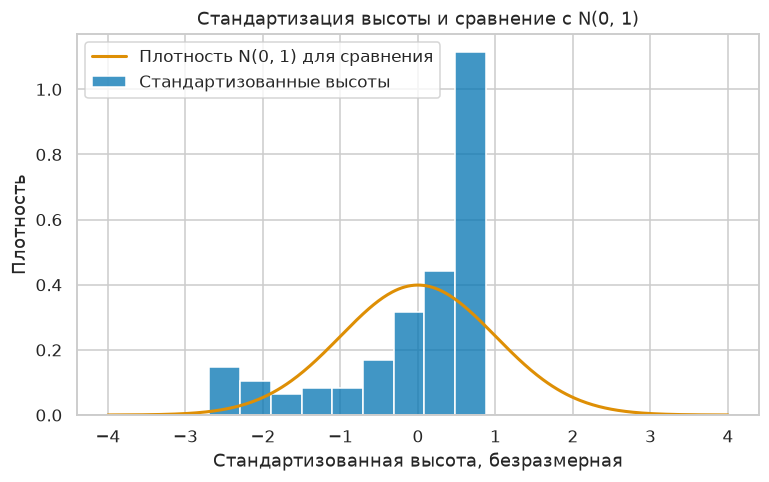

In [16]:
# Стандартизованные признаки храним отдельно от физических значений.
height_standardized = (height - height.mean()) / height.std(ddof=1)

print(f"Среднее после стандартизации: {height_standardized.mean():.6f}")
print(
    "Стандартное отклонение после стандартизации: "
    f"{height_standardized.std(ddof=1):.6f}"
)

# Проверяем исходные высоты.
shapiro_result = stats.shapiro(height)
alpha = 0.05

print(f"\nСтатистика W: {shapiro_result.statistic:.6f}")
print(f"p-value: {shapiro_result.pvalue:.6g}")

if shapiro_result.pvalue < alpha:
    print("При предпосылках теста H₀ о нормальности отвергается.")
else:
    print(
        "Недостаточно оснований отвергнуть H₀. "
        "Это не доказывает нормальность."
    )

fig, ax = plt.subplots(figsize=(8, 4.5))

sns.histplot(
    x=height_standardized,
    bins="fd",
    stat="density",
    ax=ax,
    label="Стандартизованные высоты",
)

grid = np.linspace(
    min(-4, height_standardized.min() - 0.5),
    max(4, height_standardized.max() + 0.5),
    400,
)

ax.plot(
    grid, stats.norm.pdf(grid),
    color="C1", linewidth=2,
    label="Плотность N(0, 1) для сравнения",
)

ax.set_xlabel("Стандартизованная высота, безразмерная")
ax.set_ylabel("Плотность")
ax.set_title("Стандартизация высоты и сравнение с N(0, 1)")
ax.legend()
plt.show()

Критерий Шапиро — Уилка дал W = 0,790375 и
p ≈ 8,44 · 10⁻¹². При уровне значимости 0,05 и предпосылках
теста гипотеза нормальности отвергается.

Результат согласуется с отрицательной асимметрией распределения
(−1,381). После стандартизации среднее равно нулю, а выборочное
стандартное отклонение — единице; форма распределения сохраняется.

Независимость повторных измерений пока не подтверждена,
поэтому интерпретация p-value остаётся условной.

#### Эмпирическое распределение

Эмпирическая функция распределения высоты:

$$
\widehat F_n(y)=\frac{1}{n}\sum_{i=1}^{n}
\mathbf{1}\{Y_i\le y\}.
$$

Она показывает долю измерений с высотой не больше y.
Каждое наблюдение получает вероятность 1/n; совпадающие значения
объединяют свои вероятности.

Для равновероятного выбора записи из имеющегося набора это точное
распределение. Для будущих измерений оно служит непараметрической
оценкой неизвестного распределения.

При независимых одинаково распределённых наблюдениях
эмпирическая функция распределения равномерно сходится
к истинной функции распределения (теорема Гливенко — Кантелли).
Перенос этого результата на повторные спектры требует
обоснования предпосылок.

### Independence & Estimations

In [17]:
height_estimates = pd.Series({
    "Среднее": height.mean(),
    "Медиана": height.median(),
    "Усечённое среднее (по 10% с каждого края)": stats.trim_mean(
        height, proportiontocut=0.10
    ),
    "Выборочное стандартное отклонение": height.std(ddof=1),
    "IQR": height.quantile(0.75) - height.quantile(0.25),
})

display(height_estimates.to_frame("Высота, усл. ед.").round(3))

,"Высота, усл. ед."
Среднее,34681.456
Медиана,38739.920
Усечённое среднее (по 10% с каждого края),36647.486
Выборочное стандартное отклонение,10628.572
IQR,11515.777


#### Оценки центра и разброса

Среднее значение высоты составляет 34681,456 усл. ед.,
медиана — 38739,920 усл. ед. Усечённое среднее после исключения
из расчёта по 10% наблюдений с каждого края равно 36647,486 усл. ед.

Соотношение среднего, усечённого среднего и медианы согласуется
с левосторонней асимметрией распределения. Обычное среднее
чувствительно к малым значениям; медиана устойчивее к крайним
наблюдениям. Эти оценки описывают разные характеристики
распределения и не являются взаимозаменяемыми.

Выборочное стандартное отклонение равно 10628,572 усл. ед.,
межквартильный размах — 11515,777 усл. ед.
Усечение используется только для сравнения оценок;
из исходной выборки наблюдения не удаляются.

Оценки среднего и дисперсии:

$$
\overline Y=\frac{1}{n}\sum_{i=1}^{n}Y_i,
\qquad
s_Y^2=\frac{1}{n-1}\sum_{i=1}^{n}(Y_i-\overline Y)^2.
$$

При независимых одинаково распределённых наблюдениях
с конечной дисперсией обе оценки несмещённы и состоятельны
для соответствующих параметров.

Нормальность для этих свойств не требуется. Однако независимость
и одинаковое распределение повторных спектров пока не установлены.
Эмпирическую сходимость оценок рассмотрим в совместном анализе.

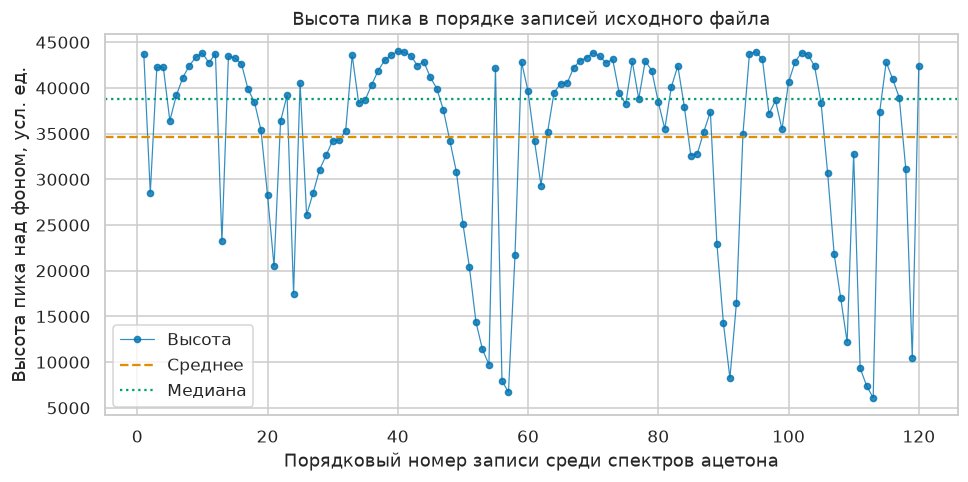

Наблюдения за границами Тьюки — без удаления:


,source_row,height_au
112,650,6089.761399
56,594,6703.319838
111,649,7388.288412
55,593,7960.448047
90,628,8245.385979
110,648,9337.035929
53,591,9735.912564
118,656,10427.727740
52,590,11390.108898
108,646,12188.382712


In [18]:
# Номер внутри группы ацетона — порядок записей в файле.
# Без временных меток его нельзя считать временем измерения.
record_order = np.arange(1, len(height) + 1)

fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(
    record_order,
    height.to_numpy(),
    marker="o",
    markersize=4,
    linewidth=0.8,
    alpha=0.8,
    label="Высота",
)

ax.axhline(
    height.mean(), color="C1",
    linestyle="--", label="Среднее",
)
ax.axhline(
    height.median(), color="C2",
    linestyle=":", label="Медиана",
)

ax.set_xlabel("Порядковый номер записи среди спектров ацетона")
ax.set_ylabel("Высота пика над фоном, усл. ед.")
ax.set_title("Высота пика в порядке записей исходного файла")
ax.legend()
plt.show()

# Сохраняем список необычно малых значений для прослеживаемости.
# Переменная outside_fences получена при построении boxplot.
print("Наблюдения за границами Тьюки — без удаления:")
display(
    features.loc[
        outside_fences,
        ["source_row", "height_au"],
    ].sort_values("height_au")
)

### Conclusions

Высота выбранной полосы ацетона после коррекции фона варьируется
от 6089,761 до 43998,517 усл. ед. Среднее составляет 34681,456,
медиана — 38739,920, выборочное стандартное отклонение —
10628,572 усл. ед.

Распределение имеет выраженную левую асимметрию (−1,381).
Усечённое среднее 36647,486 усл. ед. располагается между обычным
средним и медианой, что согласуется с влиянием малых значений
на оценку среднего.

За нижней границей Тьюки находятся 10 наблюдений (8,33%).
Они сохранены: оснований считать их ошибками измерения
по имеющимся данным недостаточно.

Критерий Шапиро — Уилка дал W = 0,790375,
p ≈ 8,44 · 10⁻¹². При предпосылках теста нормальная модель
отвергается. Стандартизация привела среднее к нулю,
а выборочное стандартное отклонение к единице, сохранив
асимметрию распределения. Для дальнейшего анализа используется
эмпирическое распределение.

В порядке записей наблюдаются плавные изменения и группы близких
значений. Это требует осторожности при предположении независимых
одинаково распределённых измерений. Без сведений о хронологии
и экспериментальных сериях нельзя установить причину структуры.

Результаты описывают вариабельность зарегистрированного сигнала
при данном протоколе и способе обработки. Связи с другими
характеристиками, выборочные оценки и их эмпирическую сходимость
рассмотрим в совместном анализе.


## Random Variable 03 — Интегральная площадь

### Description
$Z_i=\int_a^b S_i(\nu)\,d\nu$; единицы: усл. ед. $\cdot\mathrm{см}^{-1}$. Площадь не равна ширине FWHM.

Здесь обоснуем случайность измерения. Детерминированная обработка случайного спектра не исключает случайности признака.

### EDA & Distribution
Будут добавлены статистики, графики и обоснование распределения.

### Independence & Estimations
Будут добавлены оценки и ссылки на [совместный анализ](#joint).

### Conclusions
Заполним после анализа.

<a id="joint"></a>
## Joint analysis

### Dependence
Попарные диаграммы, корреляции Пирсона и Спирмена. Нулевая корреляция не доказывает независимость.

### Population & sampling
Повторный отбор с возвращением и без возвращения при разных объёмах выборки.

### Consistency of estimators
Ошибки оценок среднего и дисперсии при росте объёма выборки; математические предпосылки и ограничения эмпирической демонстрации.

### Hypothesis testing
Предварительная гипотеза: ранговая корреляция высоты и площади равна нулю. Альтернатива двусторонняя, уровень значимости 0.05. Применимость теста уточним после аудита повторов. Это не тест полной независимости.

<a id="resume"></a>
## Lab resume

### Main findings
Результатов пока нет.

### Limitations
Уточним ограничения независимости повторов, спектральной сетки и обработки.

### cat_mark_table
Идентификаторы и коэффициенты заполним по официальной таблице преподавателя.

| cat_id | notebook_link | coeff | comment |
|---|---|---|---|
| — | [Структура](#setup) | — | Подготовлена; анализ ещё не выполнен |

### References
1. Flanagan A. R., Glavin F. G. Scientific Data 12, 498 (2025). https://doi.org/10.1038/s41597-025-04848-6
2. Figshare: https://doi.org/10.6084/m9.figshare.27931131

### Research log
- v0.1: структура, определения признаков, подготовка окружения. Данные ещё не анализировались.